# Analyse de tableaux de données avec pandas

## 1 Introduction
Vous aurez besoin d’au moins 5 Go de RAM disponible pour la suite de ce TD. Si vous comptiez utiliser votre ordinateur personnel mais que ce dernier ne dispose pas de 5 Go de RAM disponible, utilisez les ordinateurs de l'école.

Le notebook contient à la fois des parties plutôt "tutoriel" : ces parties vous montrent les capacités de pandas, et vous demandent d'executer des cellules de code pré-remplies. Si l'énoncé vous fournit le résultat attendu, vérfiez simplement que le résultat que vous obtenez est correct.
Le notebook contient également des questions ainsi qu'un exercice final dans lesquels c'est à vous de trouver et ajouter les lignes de code répondant au problème !


### 1.1 Objectif
L’objectif de cette séance est de se familiariser avec la manipulation et le traitement de (potentiellement gros) tableaux de données en python, pour en ressortir une information précise. Par tableau on entend “une liste d'éléments (les lignes du tableau) possédant tous les mêmes attributs (les colonnes du tableau)”, à l’instar de ce que l’on peut trouver dans un classeur Excel ou une table de base de données SQL.
Pour ce TD, nous utiliserons le package python pandas en chargeant des tableaux depuis des fichiers csv (Comma Separated Values: fichier texte contenant des valeurs séparées par des virgules). A noter que pandas peut également charger des tableaux depuis des bases de données SQL ou fichiers Excel (non abordé ici).

### 1.2 Présentation et récupération des données
Les données que nous allons manipuler dans ce TD est un ensemble de fichiers csv (ou plus précisément “tsv” car le séparateur est le caractère “tab” et non pas une virgule) mis à disposition gratuitement par IMDB.com [sur cette page](https://datasets.imdbws.com/). La description de chaque fichier est disponible [ici](https://developer.imdb.com/non-commercial-datasets/).

Créez un dossier IMDB. téléchargez (ou copiez) les fichiers tsv compréssés (avec l'extension gz) title.ratings, title.basics, title.principals et name.basics dans le dossier IMDB Décompressez-les dans ce dossier avec l'executable gzip : 

```
ls *.gz |xargs -n1 gzip -dv
```

Une fois cela fait, en executant la cellule ci-dessous, vous devriez obtenir le résultat suivant (au nom d'utilisateur près):
```
drwxr-xr-x 2 clement clement       4096 Oct  1 00:37 ./
drwxr-xr-x 8 clement clement       4096 Sep 30 22:14 ../
-rw-r--r-- 1 clement clement  906244603 Sep 30 22:14 name.basics.tsv
-rw-r--r-- 1 clement clement 1033130568 Sep 30 22:15 title.basics.tsv
-rw-r--r-- 1 clement clement 4235431938 Sep 30 22:15 title.principals.tsv
-rw-r--r-- 1 clement clement   28201022 Sep 30 22:15 title.ratings.tsv

```

In [1]:
%%bash
# Executez cette cellule sans la modifier et vérifiez que le résultat est correct
ls -l IMDB/

total 11267116
-rwxrwxrwx 1 fattah fattah  967487584 Sep 15 14:18 name.basics.tsv
-rwxrwxrwx 1 fattah fattah  309773342 Sep 15 14:18 name.basics.tsv.gz
-rwxrwxrwx 1 fattah fattah 3004104642 Sep 15 14:19 title.akas.tsv
-rwxrwxrwx 1 fattah fattah  513813752 Sep 15 14:19 title.akas.tsv.gz
-rwxrwxrwx 1 fattah fattah 1109931478 Sep 15 14:18 title.basics.tsv
-rwxrwxrwx 1 fattah fattah  227078754 Sep 15 14:18 title.basics.tsv.gz
-rwxrwxrwx 1 fattah fattah  421050586 Sep 15 14:18 title.crew.tsv
-rwxrwxrwx 1 fattah fattah   83112277 Sep 15 14:18 title.crew.tsv.gz
-rwxrwxrwx 1 fattah fattah  259871626 Sep 15 14:17 title.episode.tsv
-rwxrwxrwx 1 fattah fattah   54653569 Sep 15 14:17 title.episode.tsv.gz
-rwxrwxrwx 1 fattah fattah 4548119980 Sep 15 14:43 title.principals.tsv
-rwxrwxrwx 1 fattah fattah   29861227 Sep 15 15:18 title.ratings.tsv
-rwxrwxrwx 1 fattah fattah    8635428 Sep 15 15:18 title.ratings.tsv.gz


## 2 Chargement avec pandas
### 2.1 Chargement d’un csv simple (10 min)
Commençons par charger un premier csv dans un DataFrame pandas grâce à sa fonction read_csv.

In [2]:
import pandas

ratings = pandas.read_csv("IMDB/title.ratings.tsv")

Affichez un aperçu de ce DataFrame en éxecutant la cellule suivante :

In [3]:
ratings

,tconst\taverageRating\tnumVotes
0,tt0000001\t5.7\t2232
1,tt0000002\t5.4\t326
2,tt0000003\t6.4\t2383
3,tt0000004\t5.0\t203
4,tt0000005\t6.2\t3097
...,...
1709563,tt9916846\t5.3\t7
1709564,tt9916848\t5.2\t7
1709565,tt9916850\t6.0\t7
1709566,tt9916852\t5.7\t7


Vous constaterez que pandas n’a pas interprété les tabs présents dans le fichier comme des
séparateurs de colonne.

**Q1)** En vous aidant de la documentation de la fonction read_csv, ajoutez l’option adéquate afin de
charger correctement le csv et ainsi obtenir cet aperçu :
```
	tconst	averageRating	numVotes
0	tt0000001	5.7	2089
1	tt0000002	5.6	283
2	tt0000003	6.5	2096
3	tt0000004	5.4	183
4	tt0000005	6.2	2832
...	...	...	...
1482925	tt9916730	7.0	12
1482926	tt9916766	7.1	24
1482927	tt9916778	7.2	37
1482928	tt9916840	7.2	10
1482929	tt9916880	8.6	8
1482930 rows × 3 columns
```

In [4]:
# Solution Q1)
ratings = pandas.read_csv("IMDB/title.ratings.tsv", sep="\t")
ratings

,tconst,averageRating,numVotes
0,tt0000001,5.7,2232
1,tt0000002,5.4,326
2,tt0000003,6.4,2383
3,tt0000004,5.0,203
4,tt0000005,6.2,3097
...,...,...,...
1709563,tt9916846,5.3,7
1709564,tt9916848,5.2,7
1709565,tt9916850,6.0,7
1709566,tt9916852,5.7,7


Vous pouvez constater que pandas a automatiquement interprété le type de chaque colonne
(float, int, …) en affichant l’attribut dtypes du DataFrame (par défaut, pandas stock les chaines de
caracteres dans un champs de type object) :

In [5]:
ratings.dtypes

tconst               str
averageRating    float64
numVotes           int64
dtype: object

### 2.2 Chargement d’un csv plus complexe
Chargez maintenant le csv “title.basics.tsv” dans un DataFrame nommé basics, de la même manière que pour “title.ratings.tsv”.

NB : Pour les très gros fichiers, il peut être judicieux d'indiquer à pandas de ne pas etre trop gourmand en RAM grâce à l'option low_memory=True

In [6]:
basics = pandas.read_csv("IMDB/title.basics.tsv", sep="\t", low_memory=True)
basics

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894,\N,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892,\N,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892,\N,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892,\N,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893,\N,1,Short
...,...,...,...,...,...,...,...,...,...
12786508,tt9916848,tvEpisode,Episode #3.17,Episode #3.17,0,2009,\N,\N,Drama
12786509,tt9916850,tvEpisode,Episode #3.19,Episode #3.19,0,2010,\N,\N,Drama
12786510,tt9916852,tvEpisode,Episode #3.20,Episode #3.20,0,2010,\N,\N,Drama
12786511,tt9916856,short,The Wind,The Wind,0,2015,\N,27,Short


Si vous affichez les types déduits par pandas pour chaque colonne, vous constaterez qu'il n’a pas réussi à inférer le bon type des colonne isAdult (colonne 4) qui devrait etre reconnue comme booléen (ou int),
startYear, endYear et runtimeMinutes (normalement des int).

In [7]:
basics.dtypes

tconst              str
titleType           str
primaryTitle        str
originalTitle       str
isAdult           int64
startYear           str
endYear             str
runtimeMinutes      str
genres              str
dtype: object

La première raison pour laquelle pandas interprete mal le contenu du fichier vient de la manière que IMDB utilise pour indiquer qu’un champ n’est pas
renseigné. En effet, comme ils le spécifient sur [la page de présentation des données](https://developer.imdb.com/non-commercial-datasets) il utilisent la
chaine de caractère “\N”, qui ne fait pas partie des symboles par défaut que pandas interprète automatiquement en tant que champs vide (la liste par défaut est renseignée dans la documentation de l’option na_values de la fonction read_csv).

**Q2)** En utilisant l’option na_values de read_csv, rechargez le csv basics. **Attention, comme le dataframe basics que vous avez chargé à la question précédente occupe beaucoup de mémoire vive, mieux vaut le supprimer avant d’essayer de le recharger ! Pour cela, utilisez l’instruction del.**

In [8]:
del basics

In [9]:
# Solution Q2)
basics = pandas.read_csv(
    "IMDB/title.basics.tsv", sep="\t", na_values=["\\N"], low_memory=True
)

C:\Users\fattah\AppData\Local\Temp\ipykernel_24928\157886577.py:2: DtypeWarning: Columns (0: runtimeMinutes) have mixed types. Specify dtype option on import or set low_memory=False.
  basics = pandas.read_csv("IMDB/title.basics.tsv", sep="\t", na_values=["\\N"], low_memory=True)


Remarquez l’avertissement :

```DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.```

pandas indique maintenant un problème à la colonne 7.

Si vous affichez le type inféré par pandas pour chaque colonne, vous constaterez en effet qu’il a réussi sauf pour la colonne 7 (runtimeMinutes) :

In [10]:
print(basics.dtypes)

tconst                str
titleType             str
primaryTitle          str
originalTitle         str
isAdult             int64
startYear         float64
endYear           float64
runtimeMinutes     object
genres                str
dtype: object


Pour comprendre quelles entrées dans la base de données posent problème à pandas, on peut tenter de forcer pandas à convertir la colonne runtimeMinutes (qui contient des "Mixed types") vers le type "float", en esperant qu'un message d'erreur nous donne plus de détails sur le probleme.

In [11]:
basics.runtimeMinutes.astype(float)

ValueError: could not convert string to float: 'Reality-TV'

Vous devez avoir obtenu une erreur avec le message suivant : 
```
ValueError: could not convert string to float: 'Reality-TV'
```
Interessons-nous donc davantage aux entrées pour lesquelles la colonne runtimeMinutes vaut "Reality-TV"

In [12]:
basics[basics.runtimeMinutes == "Reality-TV"]

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
1096183,tt10233364,tvEpisode,Rolling in the Deep Dish\tRolling in the Deep ...,0,2019,NaN,22.0,Reality-TV,NaN
2298110,tt12415330,tvEpisode,Anthony Davis High Brow Tank\tAnthony Davis Hi...,0,2017,NaN,NaN,Reality-TV,NaN
6851657,tt28535095,tvEpisode,I'm into Sharif Boys\tI'm into Sharif Boys,0,2023,NaN,NaN,Reality-TV,NaN
8301898,tt34543329,tvEpisode,Men-Oh-Pause\tMen-Oh-Pause,0,2024,NaN,41.0,Reality-TV,NaN
9042890,tt37812510,tvEpisode,Magnolia's Guide to Hot Air Ballooning\tMagnol...,0,2025,NaN,NaN,Reality-TV,NaN


On constate que pandas parse ces lignes de maniere erronnée dès la colonne originalTitle ! Et en regardant bien la colonne primaryTitle, on constate que la valeur qui aurait du etre dans originalTitle semble avoir été concatenée à tort dans la colonne primaryTitle.
Pour essayer de comprendre pourquoi, on peut afficher la ligne brute du fichier tsv associée à une de ces entrées de la BDD. Pour cela, sur un systeme Unix (Linux ou Mac), on peut utiliser le programme "grep" :

In [13]:
%%bash
grep -e tt10233364 IMDB/title.basics.tsv 

tt10233364	tvEpisode	"Rolling in the Deep Dish	"Rolling in the Deep Dish	0	2019	\N	22	Reality-TV


Un oeil averti verra alors immediatement le problème : les colonnes primaryTitle et originalTitle commencent toutes les eux par un guillement qui n'est pas refermé ! 
Hors, pandas ignore tous les caracteres speciaux (y compris les caractères servant de separateur de colonne !) compris entre deux guillements. Pour lui, le tab présent à la fin de la 1ere occurence de "Deep Dish" fait donc partie integrante de la colonne primaryTitle et n'est pas interprété comme un séparateur de colonne !

**Q3)** Pour remédier à cela, recharger le csv en utilisant l’option quoting=csv.QUOTE_NONE de la fonction read_csv, qui permet de ne donner aucun sens particulier au caractère guillemet. Comme pour la précédente question, pensez à bien détruire le dataframe basics avant de le recharger pour économiser de l'espace en RAM.

In [47]:
# Solution Q3)
import csv

del basics
basics = pandas.read_csv(
    "IMDB/title.basics.tsv",
    sep="\t",
    na_values="\\N",
    quoting=3,
    low_memory=True,
)

Vous pouvez maintenant constater que pandas a correctement interprété les types de chaque colonne : 

In [48]:
basics.dtypes

tconst                str
titleType             str
primaryTitle          str
originalTitle         str
isAdult             int64
startYear         float64
endYear           float64
runtimeMinutes    float64
genres                str
dtype: object

## 3 Accès aux éléments d’un DataFrame
### 3.1 df.loc[] , df.iloc[] , df[]
Les DataFrame possèdent deux dimensions. L’attribut “loc” d’un DataFrame permet d’adresser la
première (les lignes) via un nom d’index et la seconde (les colonnes) via un nom de colonne.
Vous pouvez afficher la liste des index et des colonnes via les attributs “index” et “colonne” d’un
DataFrame :

In [49]:
ratings.index

RangeIndex(start=0, stop=1709568, step=1)

In [51]:
ratings.columns

Index(['tconst', 'averageRating', 'numVotes'], dtype='str')

In [52]:
basics.loc[42, "startYear"]

np.float64(1896.0)

Il est possible d'accéder à plusieurs colonnes pour un index donné, ou plusieurs index pour une
colonne donné, auquel cas pandas retournera une Series :

In [19]:
s = basics.loc[42, ["originalTitle", "startYear"]]
print(s)
print(f"{type(s)=}")

originalTitle    Le bivouac
startYear            1896.0
Name: 42, dtype: object
type(s)=<class 'pandas.Series'>


In [20]:
s = basics.loc[[42, 2023], "originalTitle"]
print(s)
print(f"{type(s)=}")

42                        Le bivouac
2023    Battle in the Virginia Hills
Name: originalTitle, dtype: str
type(s)=<class 'pandas.Series'>


Il est possible d’extraire plusieurs index et colonnes à la fois, auquel cas pandas retournera un
DataFrame :

In [21]:
d = basics.loc[[42, 2023], ["originalTitle", "startYear"]]
print(d)
print(f"{type(d)=}")

                     originalTitle  startYear
42                      Le bivouac     1896.0
2023  Battle in the Virginia Hills     1912.0
type(d)=<class 'pandas.DataFrame'>


Il est également possible de faire les mêmes accès à des éléments/lignes/colonnes/sous-DataFrame via les numéros de lignes et colonnes grâce à l’attribut iloc :

In [22]:
basics.iloc[[42, 2023], [2, 7]]

,primaryTitle,runtimeMinutes
42,Le bivouac,1.0
2023,Battle in the Virginia Hills,NaN


Vous pouvez utiliser le symbole “:” sur une des dimensions de l’attribut loc ou iloc afin de sélectionner tous les champs d’une dimension et ainsi récupérer une ligne ou colonne entière.

In [23]:
ratings.loc[:, "numVotes"]

0          2232
1           326
2          2383
3           203
4          3097
           ... 
1709563       7
1709564       7
1709565       7
1709566       7
1709567      12
Name: numVotes, Length: 1709568, dtype: int64

In [24]:
basics.loc[5, :]

tconst                    tt0000006
titleType                     short
primaryTitle      Chinese Opium Den
originalTitle     Chinese Opium Den
isAdult                           0
startYear                    1894.0
endYear                         NaN
runtimeMinutes                  1.0
genres                        Short
Name: 5, dtype: object

Dans le cas des colonnes, il existe une possibilité supplémentaire : l'opérateur [] ou “.” directement appliqué au DataFrame :

In [53]:
basics.startYear

0           1894.0
1           1892.0
2           1892.0
3           1892.0
4           1893.0
             ...  
12786508    2009.0
12786509    2010.0
12786510    2010.0
12786511    2015.0
12786512    2014.0
Name: startYear, Length: 12786513, dtype: float64

In [26]:
basics["titleType"]

0               short
1               short
2               short
3               short
4               short
              ...    
12786508    tvEpisode
12786509    tvEpisode
12786510    tvEpisode
12786511        short
12786512    tvEpisode
Name: titleType, Length: 12786513, dtype: str

## 4 Opérations sur les colonnes
### 4.1 Opérations arithmétiques entre colonnes

In [54]:
ratings.numVotes * ratings.averageRating

0          12722.4
1           1760.4
2          15251.2
3           1015.0
4          19201.4
            ...   
1709563       37.1
1709564       36.4
1709565       42.0
1709566       39.9
1709567       90.0
Length: 1709568, dtype: float64

### 4.2 Statistiques

In [28]:
N = ratings.numVotes.sum()
moy = ratings.averageRating.mean()
std = ratings.averageRating.std()

La méthode describe permet d’avoir rapidement des informations sur la distributions des valeurs dans une colonne de valeurs numériques :

In [29]:
ratings.describe()

,averageRating,numVotes
count,1.709568e+06,1.709568e+06
mean,6.973842e+00,1.039848e+03
std,1.395309e+00,1.829960e+04
min,1.000000e+00,5.000000e+00
25%,6.200000e+00,1.200000e+01
50%,7.200000e+00,2.600000e+01
75%,7.900000e+00,1.010000e+02
max,1.000000e+01,3.237527e+06


### 4.3 Application de fonctions numpy

In [30]:
import numpy as np

np.mod(basics.startYear, 10)

0           4.0
1           2.0
2           2.0
3           2.0
4           3.0
           ... 
12786508    9.0
12786509    0.0
12786510    0.0
12786511    5.0
12786512    4.0
Name: startYear, Length: 12786513, dtype: float64

### 4.4 Application de fonctions personnalisées

In [55]:
basics.startYear.apply(lambda x: x / 2 if x % 2 == 0 else 2 * x + 1)

KeyboardInterrupt: 

## 5 Ajout d’une colonne dans un DataFrame

In [32]:
basics["runtimeHours"] = basics["runtimeMinutes"] / 60
basics["isOld"] = basics["startYear"] < 1992
basics[["originalTitle", "runtimeMinutes", "runtimeHours", "startYear", "isOld"]]

,originalTitle,runtimeMinutes,runtimeHours,startYear,isOld
0,Carmencita,1.0,0.016667,1894.0,True
1,Le clown et ses chiens,5.0,0.083333,1892.0,True
2,Pauvre Pierrot,5.0,0.083333,1892.0,True
3,Un bon bock,12.0,0.200000,1892.0,True
4,Blacksmith Scene,1.0,0.016667,1893.0,True
...,...,...,...,...,...
12786508,Episode #3.17,NaN,NaN,2009.0,False
12786509,Episode #3.19,NaN,NaN,2010.0,False
12786510,Episode #3.20,NaN,NaN,2010.0,False
12786511,The Wind,27.0,0.450000,2015.0,False


## 6 Filtrage / Indexage logique

Directement avec l'opérateur DataFrame[] : 

In [33]:
ratings[ratings.numVotes > 1e6]

,tconst,averageRating,numVotes
31413,tt0050083,9.0,1002499
47864,tt0068646,9.2,2255510
50446,tt0071562,9.0,1512754
52130,tt0073486,8.6,1166846
53720,tt0075314,8.2,1041980
...,...,...,...
1373994,tt4154796,8.4,1487129
1414393,tt4574334,8.6,1738314
1558171,tt6751668,8.5,1195397
1587991,tt7286456,8.3,1725353


Ou bien avec l'opérateur DataFrame.loc[] : 

In [35]:
basics.loc[basics.startYear > 2020, "runtimeMinutes"]

38009         4.0
56262        30.0
58033        16.0
61002        10.0
64090        85.0
            ...  
12782342    111.0
12784678      NaN
12785670     96.0
12786021     33.0
12786169      NaN
Name: runtimeMinutes, Length: 2658390, dtype: float64

**Q4)** Extraire dans un DataFrame “movies” les éléments de basics dont l’attribut “titleType” est “movie”.

In [34]:
# Solution Q4)
movies = basics[basics.titleType == "movie"]
movies

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres,runtimeHours,isOld
8,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance,0.750000,True
144,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport",1.666667,True
498,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN,1.666667,True
570,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography",1.166667,True
587,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama,1.500000,True
...,...,...,...,...,...,...,...,...,...,...,...
12786407,tt9916622,movie,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,0,2015.0,NaN,57.0,Documentary,0.950000,False
12786431,tt9916680,movie,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,0,2007.0,NaN,100.0,Documentary,1.666667,False
12786443,tt9916706,movie,Dankyavar Danka,Dankyavar Danka,0,2013.0,NaN,NaN,Comedy,NaN,False
12786453,tt9916730,movie,6 Gunn,6 Gunn,0,2017.0,NaN,116.0,Drama,1.933333,False


## 7 Fusion de DataFrame
Il est possible de croiser les informations de deux DataFrame différents. Pour cela, pandas possède
entre autres la fonction merge.

**Q5)** Après avoir étudié la documentation de la fonction merge, créer le DataFrame “rated_movies”
qui regroupe les informations des DataFrames “movies” et “ratings” uniquement pour les films
possédant une note sur IMDB.

Les cinq premiers éléments de ce DataFrame doivent être ceux-ci :
``` 
   averageRating                   primaryTitle
0            5.4                     Miss Jerry
1            5.2  The Corbett-Fitzsimmons Fight
2            4.4                       Bohemios
3            6.0    The Story of the Kelly Gang
4            5.7               The Prodigal Son
5            4.3             Robbery Under Arms
```

In [56]:
# Solution Q5)
rated_movies = movies.merge(ratings, on="tconst")
rated_movies[["averageRating", "primaryTitle"]].head(6)

,averageRating,primaryTitle
0,5.3,Miss Jerry
1,5.3,The Corbett-Fitzsimmons Fight
2,3.9,Bohemios
3,6.0,The Story of the Kelly Gang
4,5.0,The Prodigal Son
5,3.7,Robbery Under Arms


## 8 Regroupement de lignes
Il est possible de regrouper les lignes d’un DataFrame qui possède la même valeur pour une
colonne donnée, et d’ensuite extraire des statistiques sur ces groupes.

In [37]:
movies.groupby("startYear").tconst.count()

startYear
1894.0     1
1896.0     1
1897.0     2
1898.0     6
1899.0     8
          ..
2028.0    95
2029.0    18
2030.0     8
2031.0     2
2032.0     2
Name: tconst, Length: 138, dtype: int64

In [38]:
movies.groupby("startYear").runtimeMinutes.mean()

startYear
1894.0     45.000000
1896.0     61.000000
1897.0    100.000000
1898.0           NaN
1899.0    135.000000
             ...    
2028.0    115.750000
2029.0           NaN
2030.0    143.333333
2031.0           NaN
2032.0           NaN
Name: runtimeMinutes, Length: 138, dtype: float64

## 9 Tracé de graphes
### 9.1 Histogramme
La méthode hist des DataFrame permet de tracer l’histogramme de toutes les colonnes à valeurs numériques du DataFrame.

array([[<Axes: title={'center': 'averageRating'}>,
        <Axes: title={'center': 'numVotes'}>]], dtype=object)

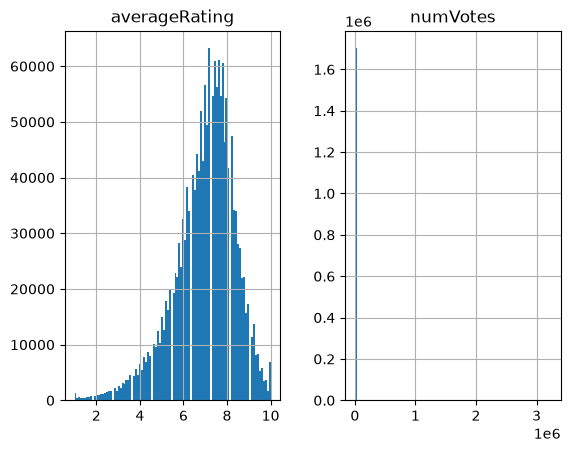

In [39]:
ratings.hist(bins=100)

On peut également l’appeler sur une colonne en particulier :

<Axes: >

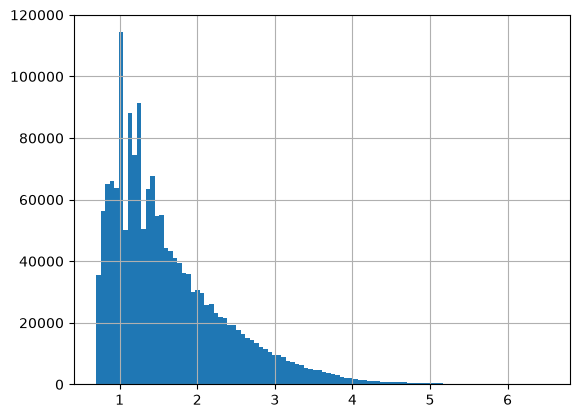

In [40]:
np.log10(ratings.numVotes).hist(bins=100)

### 9.2 Courbes
On peut simplement tracer les valeurs d’une colonne en fonction d’une autre colonne grâce à la méthode “plot” de DataFrame. L’option “kind” permet de choisir le type de graphe.

<Axes: xlabel='startYear', ylabel='numVotes'>

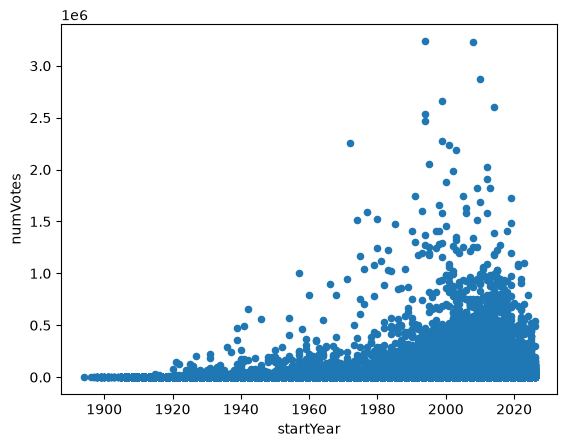

In [41]:
rated_movies.plot("startYear", "numVotes", kind="scatter")

### 9.3 Pie Charts

<Axes: >

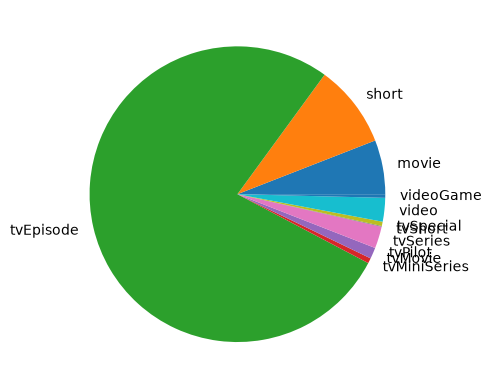

In [42]:
basics.groupby("titleType").titleType.count().plot.pie()

## 10 Filtrages de csv volumineux

Comme vous pouvez le constater, certains fichiers sont très gros : jusqu’à 2.7 Go pour la table “title.principals.tsv” listant les acteurs principaux de l’ensemble des titres de IMDB. Cela peut rendre long, voire impossible en fonction de la quantité de mémoire vive que possède votre ordinateur, le chargement de ces tables en RAM.
Pour la suite du TD, afin de ne pas avoir à manipuler l'intégralité de la table title.principal.tsv, nous allons la filtrer pour ne garder que les lignes associées à un élément de type “movie”. Nous écrirons le résultat de ce filtrage dans un fichier tsv plus petit “movie.principals.tsv” afin de pouvoir le recharger facilement ultérieurement.

### 10.1 Filtrage par morceaux
Avec l’option “chunksize” de la fonction “read_csv”, il est possible de charger un gros fichier csv petit bout par petit bout. Ainsi on peut filtrer chaque petit bout en stockant le résultat de ce filtrage partiel dans une liste temporaire avant de finalement concatener tous ces morceaux filtrés en un unique DataFrame :

In [ ]:
from tqdm import tqdm

momatilin = []
movies_ids = movies.tconst.values
with pandas.read_csv(
    "IMDB/title.principals.tsv",
    sep="\t",
    na_values=["\\N"],
    quoting=csv.QUOTE_NONE,
    chunksize=100000,
) as reader:
    for k, chunk in tqdm(enumerate(reader)):
        subchunk = chunk[chunk.tconst.isin(movies_ids)]
        momatilin.append(subchunk)
movie_principals_list = pandas.concat(momatilin)

1018it [04:21,  3.89it/s]


### 10.2 Ecriture de la table dans un fichier
La méthode “to_csv” des DataFrame permet de simplement écrire un fichier csv :

In [59]:
movie_principals_list.to_csv(
    "IMDB/movie.principals.tsv",
    index=False,
    sep="\t",
    na_rep="\\N",
    quoting=csv.QUOTE_NONE,
)

**Q6)** A partir des morceaux de code précédents, créer le DataFrame “movies_actor_list” et le fichier “movie.actors.tsv”, qui ne contiennent que les informations de “title.principals.tsv” concernant **les rôles d’acteurs/actrices dans des films de cinéma**.

In [ ]:
# Solution Q6)
momatilin = []
movies_ids = movies.tconst.values
with pandas.read_csv(
    "IMDB/title.principals.tsv",
    sep="\t",
    na_values=["\\N"],
    quoting=csv.QUOTE_NONE,
    chunksize=100000,
) as reader:
    for chunk in tqdm(reader):
        subchunk = chunk[
            chunk.tconst.isin(movies_ids) & chunk.category.isin(["actor", "actress"])
        ]
        momatilin.append(subchunk)
movies_actor_list = pandas.concat(momatilin)
movies_actor_list.to_csv(
    "IMDB/movie.actors.tsv", index=False, sep="\t", na_rep="\\N", quoting=csv.QUOTE_NONE
)
movies_actor_list

1018it [04:29,  3.78it/s]


,tconst,ordering,nconst,category,job,characters
28,tt0000009,1,nm0063086,actress,NaN,"[""Miss Geraldine Holbrook (Miss Jerry)""]"
29,tt0000009,2,nm0183823,actor,NaN,"[""Mr. Hamilton""]"
30,tt0000009,3,nm1309758,actor,NaN,"[""Chauncey Depew - the Director of the New Yor..."
31,tt0000009,4,nm0574726,actress,NaN,"[""Olivia Prattsby""]"
1097,tt0000502,1,nm0215752,actor,NaN,NaN
...,...,...,...,...,...,...
101748619,tt9916730,4,nm4852679,actor,NaN,NaN
101748620,tt9916730,5,nm9050497,actor,NaN,NaN
101748621,tt9916730,6,nm7365126,actress,NaN,NaN
101748622,tt9916730,7,nm1576284,actress,NaN,NaN


**Q7)** A partir du fichier “name.basics.tsv”, créer un DataFrame “movie_actors_basics”, que vous écrirez dans un fichier “movie_actors.basics.tsv”, ne contenant que les informations personnelles relatives aux acteurs/actrices ayant joué dans un film de cinéma (c'est à dire les acteurs/actrices apparaissant au moins une fois dans le dataframe movies_actor_list)

In [61]:
# Solution Q7)
actor_ids = movies_actor_list.nconst.unique()
subchunks = []
with pandas.read_csv(
    "IMDB/name.basics.tsv",
    sep="\t",
    na_values=["\\N"],
    quoting=csv.QUOTE_NONE,
    chunksize=100000,
) as reader:
    for chunk in tqdm(reader):
        subchunk = chunk[chunk.nconst.isin(actor_ids)]
        subchunks.append(subchunk)
movie_actors_basics = pandas.concat(subchunks)
movie_actors_basics.to_csv(
    "IMDB/movie_actors.basics.tsv",
    index=False,
    sep="\t",
    na_rep="\\N",
    quoting=csv.QUOTE_NONE,
)
movie_actors_basics

157it [01:10,  2.23it/s]


,nconst,primaryName,birthYear,deathYear,primaryProfession,knownForTitles
0,nm0000001,Fred Astaire,1899.0,1987.0,"actor,miscellaneous,producer","tt0072308,tt0031983,tt0050419,tt0025164"
1,nm0000002,Lauren Bacall,1924.0,2014.0,"actress,miscellaneous,soundtrack","tt0037382,tt0117057,tt0075213,tt0038355"
2,nm0000003,Brigitte Bardot,1934.0,2025.0,"actress,music_department,producer","tt0057345,tt0049189,tt0056404,tt0054452"
3,nm0000004,John Belushi,1949.0,1982.0,"actor,writer,music_department","tt0072562,tt0077975,tt0080455,tt0078723"
4,nm0000005,Ingmar Bergman,1918.0,2007.0,"writer,director,actor","tt0050986,tt0083922,tt0069467,tt0050976"
...,...,...,...,...,...,...
15655691,nm9993652,Kamil Borowiecki,NaN,NaN,actor,tt8739208
15655695,nm9993656,Jerzy Ciurlok,NaN,NaN,actor,tt8739208
15655714,nm9993680,Christopher-Lawson Palmer,NaN,NaN,actor,"tt8295580,tt21745568,tt10427366,tt21047844"
15655727,nm9993693,Apsara Rani,1996.0,NaN,"actress,archive_footage","tt12856788,tt39440956,tt13847502,tt8302382"


# 11 Exercices

1) Combien de films ont obtenu la note de 10/10 ?
2) Afficher l’histogramme des notes des films sortis ces 10 dernières années.
3) Donner les noms, les nombres de votes et les notes moyennes des 5 films les mieux notés et ayant plus de 50000 notes.
4) Donner les noms, notes moyennes, nombres de votes et dates de sortie des 5 comédies avec plus de 50000 notes les mieux notées de ces 20 dernières années.
5) Donner la moyenne et écart-type des notes par genre de film (indice : vous pourrez regarder la méthode Series.str.split et DataFrame.explode).
6) Tracer l'évolution de la note moyenne des films d’action en fonction de l’année de sortie.
7) Donner la liste des 5 acteurs vivants ayant joué dans le plus de films.
8) Donner la liste des 5 acteurs ayant joué dans au moins 5 films, avec la filmographie la mieux notée.
9) Tracer le graphe “Nombre de films joués” versus “Note moyenne de la filmographie”.

In [62]:
# Solution exo 1)
nb_films_10 = (rated_movies.averageRating == 10).sum()
print(f"{nb_films_10} films ont obtenu la note de 10/10")

16 films ont obtenu la note de 10/10


<Axes: >

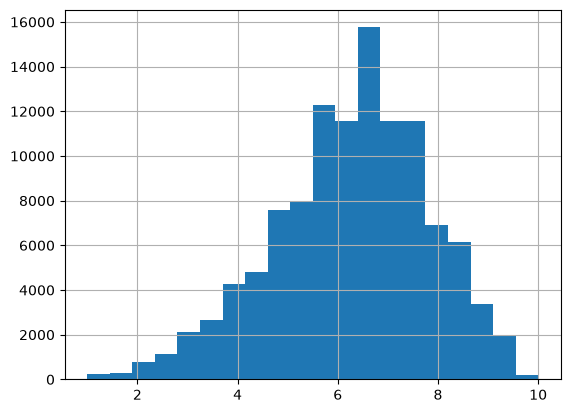

In [63]:
# Solution exo 2)
last_year = rated_movies.startYear.max()
recent_movies = rated_movies[rated_movies.startYear >= last_year - 10]
recent_movies.averageRating.hist(bins=20)

In [64]:
# Solution exo 3)
top5_votes = (
    rated_movies[rated_movies.numVotes > 50000]
    .sort_values("averageRating", ascending=False)
    .head(5)
)
top5_votes[["primaryTitle", "numVotes", "averageRating"]]

,primaryTitle,numVotes,averageRating
62395,The Shawshank Redemption,3237527,9.3
37428,The Godfather,2255510,9.2
140239,The Dark Knight,3225950,9.1
60817,Schindler's List,1602885,9.0
24258,12 Angry Men,1002499,9.0


In [65]:
# Solution exo 4)
last_year = rated_movies.startYear.max()
comedies = rated_movies[
    rated_movies.genres.str.contains("Comedy", na=False)
    & (rated_movies.numVotes > 50000)
    & (rated_movies.startYear >= last_year - 20)
]
top5_comedies = comedies.sort_values("averageRating", ascending=False).head(5)
top5_comedies[["primaryTitle", "averageRating", "numVotes", "startYear"]]

,primaryTitle,averageRating,numVotes,startYear
206634,The Intouchables,8.5,1042036,2011.0
167907,3 Idiots,8.4,489548,2009.0
228126,Lost Ladies,8.3,62159,2023.0
136187,Toy Story 3,8.3,990303,2010.0
336549,Dil Bechara,8.3,138591,2020.0


In [66]:
# Solution exo 5)
genres_exploded = rated_movies.assign(
    genres=rated_movies.genres.str.split(",")
).explode("genres")
genres_exploded.groupby("genres").averageRating.agg(["mean", "std"])

,mean,std
genres,,
Action,5.748605,1.375294
Adult,5.631895,1.180646
Adventure,5.854775,1.339698
Animation,6.320798,1.333077
Biography,6.922182,1.105910
Comedy,5.887623,1.280974
Crime,5.973261,1.184427
Documentary,7.173551,1.129389
Drama,6.205660,1.199401


<Axes: xlabel='startYear'>

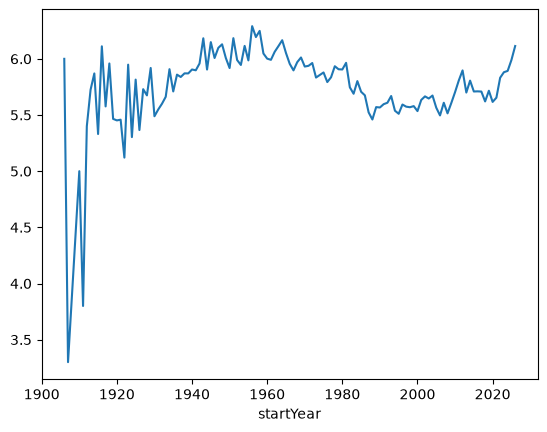

In [67]:
# Solution exo 6)
action_movies = rated_movies[rated_movies.genres.str.contains("Action", na=False)]
action_movies.groupby("startYear").averageRating.mean().plot()

In [68]:
# Solution exo 7)
alive_actor_ids = movie_actors_basics[movie_actors_basics.deathYear.isna()].nconst
film_counts = (
    movies_actor_list[movies_actor_list.nconst.isin(alive_actor_ids)]
    .groupby("nconst")
    .tconst.count()
)
top5_alive_ids = film_counts.sort_values(ascending=False).head(5)
movie_actors_basics.set_index("nconst").loc[top5_alive_ids.index, "primaryName"]

nconst
nm0103977         Brahmanandam
nm0415549    Jagathy Sreekumar
nm0007106        Shakti Kapoor
nm0000616         Eric Roberts
nm0045119          Aruna Irani
Name: primaryName, dtype: str

In [69]:
# Solution exo 8)
actor_ratings = movies_actor_list.merge(
    rated_movies[["tconst", "averageRating"]], on="tconst"
)
actor_stats = actor_ratings.groupby("nconst").averageRating.agg(
    nb_films="count", note_moyenne="mean"
)
actor_stats_5plus = actor_stats[actor_stats.nb_films >= 5]
top5_filmography_ids = actor_stats_5plus.sort_values(
    "note_moyenne", ascending=False
).head(5)
movie_actors_basics.set_index("nconst").loc[top5_filmography_ids.index, "primaryName"]

nconst
nm14175849          Victor Schiavon
nm13498791     Prince Oak Oakleyski
nm8583399         Chitto Buenrostro
nm7254965     El Flaco De Michoacan
nm2419094     Mahalinga Bhagavathar
Name: primaryName, dtype: str

<Axes: xlabel='nb_films', ylabel='note_moyenne'>

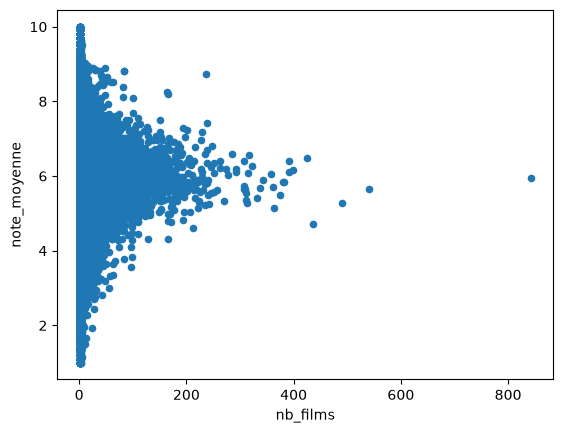

In [70]:
# Solution exo 9)
actor_stats.plot.scatter(x="nb_films", y="note_moyenne")

# 12 Exercice final

Créez un utilitaire en ligne de commande qui, lorsqu'executé depuis un terminal, affiche un message d'accueil et demande à l'utilisateur de choisir parmi une des fonctionnalités suivantes : 
    a) affichage d'un profil d'acteur/actrice
    b) affichage du top 5 des films par genre et par année

Dans le cas ou l'utilisateur a fait le choix a), l'utilitaire doit demander à l'utilisateur de renseigner un nom d'acteur. 
* Si le nom renseigné existe bien dans la base, l'utilitaire doit afficher :
  * les infos sur l'acteur/actrice (date de naissance, age, ...)
  * la note moyenne de sa filmographie
  * un histogramme montrant le nombre de films dans lequel la personne a joué en fonction des années
* Dans le cas ou le nom ne correspond à aucun acteur/Actrice, l'utilitaire propose les 5 noms les plus proches.
* Apres avoir afficher tout cela, l'utilitaire revient à l'accueil.


Dans le cas ou l'utilisateur a fait le choix b), l'utilitaire doit afficher la liste de tous les genres disponibles dans la base, et demander à l'utilisateur d'en choisir un parmi eux. Puis l'utilitaire demande à l'utilisateur de renseigner une année. 
* Dans le cas ou il existe un ou plusieurs films du genre selectionné pour l'année renseignée, l'utilitaire affiche les (au plus) 5 films les mieux notés de ce genre pour cette année.
* Dans le cas ou aucun film de ce genre n'a été réalisé cette année là, l'utilitaire demande à l'utilisateur de renseigner une autre année.
* Apres avoir afficher, l'utilitaire revient à l'accueil.

## Solution exercice final

L'utilitaire ci-dessous est écrit dans le fichier `imdb_cli.py` (via la magic `%%writefile`), car il est destiné à être lancé depuis un terminal (`python imdb_cli.py`) et utilise `input()` pour dialoguer avec l'utilisateur, ce qui n'est pas adapté à une exécution automatique de notebook.

Il réutilise les fichiers déjà produits/filtrés plus haut (`IMDB/movie.actors.tsv` et `IMDB/movie_actors.basics.tsv`) afin de rester rapide au démarrage, plutôt que de recharger l'intégralité de `title.principals.tsv` ou `name.basics.tsv`.

Writing imdb_cli.py
